# 03 — Preprocessing and Train/Test Split
**Goal:** define X and y without leakage, create a stratified 80/20 split, and assess whether
dimensionality reduction is useful.

In [1]:
import sys
from pathlib import Path

# Make the project's src/ package importable when running from notebooks/
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "electrical_grid_stability.csv"

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 140)
%matplotlib inline

In [2]:
from src.preprocessing import FEATURE_COLUMNS, TARGET_COLUMN, load_and_split_data

print("Features (X):", FEATURE_COLUMNS)
print("Target (y):", TARGET_COLUMN)
print("Excluded: 'stab' (target leakage — stabf is derived from it)")

X_train, X_test, y_train, y_test = load_and_split_data(DATA_PATH, test_size=0.20, random_state=42)
print("\nTrain:", X_train.shape, " Test:", X_test.shape)
pd.DataFrame({"train %": y_train.value_counts(normalize=True) * 100,
              "test %": y_test.value_counts(normalize=True) * 100}).round(2)

Features (X): ['tau1', 'tau2', 'tau3', 'tau4', 'p1', 'p2', 'p3', 'p4', 'g1', 'g2', 'g3', 'g4']
Target (y): stabf
Excluded: 'stab' (target leakage — stabf is derived from it)

Train: (8000, 12)  Test: (2000, 12)


,train %,test %
stabf,,
unstable,63.8,63.8
stable,36.2,36.2


**Interpretation:** the stratified split keeps the 63.8/36.2 class ratio in both sets. The 2,000
test records are held out and are only used for final evaluation; all model selection is done
with cross-validation on the 8,000 training records.

**Scaling:** Logistic Regression is sensitive to feature scale (`tau` ranges up to 10 while `g` is
at most 1), so a `StandardScaler` is placed **inside** a scikit-learn `Pipeline`. The scaler is
then fitted on the training data (or training folds) only, preventing test-set information from
leaking into preprocessing. Random Forest splits on thresholds and does not need scaling.

## Dimensionality reduction

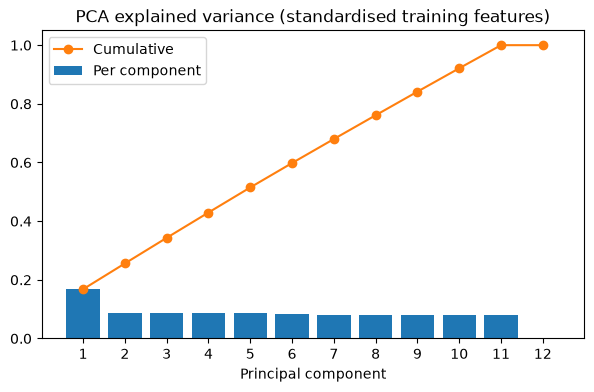

,component,explained_variance_ratio,cumulative
0,1,0.1680,0.1680
1,2,0.0879,0.2559
2,3,0.0873,0.3432
3,4,0.0862,0.4295
4,5,0.0856,0.5150
5,6,0.0832,0.5982
6,7,0.0817,0.6800
7,8,0.0811,0.7611
8,9,0.0805,0.8416
9,10,0.0797,0.9213


In [3]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

pca = PCA().fit(StandardScaler().fit_transform(X_train))
pca_df = pd.DataFrame({"component": range(1, 13),
                       "explained_variance_ratio": pca.explained_variance_ratio_,
                       "cumulative": pca.explained_variance_ratio_.cumsum()}).round(4)
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(pca_df["component"], pca_df["explained_variance_ratio"], label="Per component")
ax.plot(pca_df["component"], pca_df["cumulative"], "o-", color="tab:orange", label="Cumulative")
ax.set_xticks(range(1, 13)); ax.set_xlabel("Principal component"); ax.legend()
ax.set_title("PCA explained variance (standardised training features)")
plt.show()
pca_df

**Interpretation:**
- Component 12 explains **0%** of the variance — PCA confirms that the 12 features only span 11
  dimensions, because `p1 = −(p2 + p3 + p4)`.
- The remaining 11 components each explain roughly 8–9% (the first ≈ 17% captures the shared power
  variation). There is no small set of components that keeps most of the information, so PCA would
  discard useful signal without simplifying the problem. PCA is **not** used for modelling.
- The appropriate dimensionality reduction is to remove the exactly redundant `p1`. Its effect is
  tested with cross-validation in notebook 07 (feature ablation). Because it carries no extra
  information, the main experiments keep all 12 documented features for interpretability, and the
  ablation shows whether dropping it changes results.